<a href="https://colab.research.google.com/github/bmulaw/ComputerVision/blob/main/ComputerVision_lab2_SAM_ObjectDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Team Name/Member: Bernard MULAW and John BRITTO
#### Date: 09/11/2026

# **Part 1: Segmentation Metrics and Their Pitfalls**

#### *Segmentation is a pixel-level classification task. But how do we measure success? The most common metrics are: **IoU, Dice Coefficient, and Pixel Accuracy**. The goal is to implement these metrics and discover a critical trap: Pixel Accuracy can be misleading when classes are imbalanced*

In [1]:
import platform
print(platform.python_version())

3.13.18


In [2]:
%pip -q install "opencv-python" "ultralytics" "segmentation-models-pytorch" "torch" "scikit-learn" "torchvision"

In [3]:
import torch
import segmentation_models_pytorch as smp
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from ultralytics import YOLO

# U-NET encoder
_ = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", classes=1)

# DeepLab V3
_ = deeplabv3_resnet50(weights=DeepLabV3_ResNet50_Weights.DEFAULT)

# Mask R-CNN
_ = maskrcnn_resnet50_fpn(weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT)

# DETR
# _ = torch.hub.load("facebookreasearch/detr", "detr_resnet50", pretrained=True)

# YOLOv8n
_ = YOLO("yolov8n.pt")

print("All weights downloaded (U-Net, DeepLab v3, Mask R-CNN, DETR, YOLO")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:01<00:00, 130MB/s]


Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 135MB/s]


All weights downloaded (U-Net, DeepLab v3, Mask R-CNN, DETR, YOLO


In [4]:
print(torch.__version__)
torch.cuda.is_available()

2.14.1+cpu


False

## Task 1.1: Implement Segmentation Metrics

In [5]:
import numpy as np

def iou_score(pred, true):
    """ pred: binary mask (H, W)
        true: binary mask (H, W)
        Return: IoU
    """
    # https://stackoverflow.com/questions/49338166/python-intersection-over-union
    pred = np.asarray(pred).astype(bool)
    true = np.asarray(true).astype(bool)
    intersection = pred * true # Logical AND
    union = pred + true # Logical OR

    # intersection = np.intersect1d(pred, true)
    # union = len(pred | true)
    # print("union", union.sum())
    # print("intersection", intersection.sum())
    return intersection.sum()/float(union.sum()) if union.sum() != 0 else 1.0


def dice_coefficient(pred, true) -> float:
    # Return: Dice coefficient
    numinator = 2 * len(pred & true)
    denominator = len(pred) + len(true)
    # print("numinator", numinator, "denominator", denominator)
    return numinator/ denominator


def pixel_accuracy(pred, true) -> float:
    # Return: Pixel accuracy
    correct = 0
    total = 0
    for i in range(len(true)):
        for j in range(len(true[i])):
            if pred[i][j] == true[i][j]: correct += 1
            total += 1
    return correct/total


def multi_class_iou(pred, true, num_classes):
    """
        pred: (H, W) long tensor, class label per pixel
        true: (H, W) long tensor
        Return: (ious , miou), where ious is an array of per-class IoU
        Note: if a class is absent in both pred and true, return NaN for that class
    """
    ious = []
    for cls in range(num_classes):
        pred_mask = (pred == cls)
        true_mask = (true == cls)

        intersection = (pred_mask * true_mask).sum().item()
        union = (pred_mask + true_mask).sum().item()

        ious.append(intersection / union) if union != 0 else ious.append(float('nan'))

    # Calculate mean IoU ignoring NaN values --> got from AI
    valid_ious = [iou for iou in ious if not torch.isnan(torch.tensor(iou))]
    miou = sum(valid_ious) / len(valid_ious) if len(valid_ious) > 0 else float('nan')

    return ious, miou

In [6]:
true_mask = np.array([[0 ,1 ,1] ,[0 ,1 ,0] ,[1 ,0 ,0]])
pred_mask = np.array([[0 ,1 ,1] ,[0 ,1 ,0] ,[1 ,0 ,0]])
assert iou_score(pred_mask , true_mask) == 1.0
assert dice_coefficient(pred_mask, true_mask) == 1.0

In [7]:
pred_mask = 1 - true_mask
# print(pred_mask, "\n\n", true_mask)
# print(iou_score(pred_mask, true_mask))
assert iou_score(pred_mask, true_mask) == 0.0

In [8]:
pred_mask = np.array([[1 ,1 ,0] ,[0 ,1 ,0] ,[1 ,0 ,0]])
print("IoU: ", iou_score(pred_mask, true_mask))
print("Dice: ", dice_coefficient(pred_mask, true_mask))
print("Pixel Acc:", pixel_accuracy(pred_mask, true_mask))

IoU:  0.6
Dice:  1.0
Pixel Acc: 0.7777777777777778


## Task 1.2: Imbalanced Data Trap

In [9]:
H, W = 100, 100
true_mask = np.zeros((H,W), dtype=np.uint8)
true_mask[40:60, 40:60] = 1  # 4% foreground

# Predictor: predict everything as background
pred_mask = np.zeros_like(true_mask)
print ("IoU: ", iou_score(pred_mask, true_mask))
print("Dice: ", dice_coefficient(pred_mask, true_mask))
print("Pixel Acc:", pixel_accuracy(pred_mask, true_mask))

IoU:  0.0
Dice:  1.0
Pixel Acc: 0.96


## Task 1.3: Multi-Class Segmentation Metrics

In [10]:
H, W = 100, 100
true_mask = np.zeros((100,100), dtype=np.uint8)
true_mask[20:50, 20:50] = 1
true_mask[60:90, 60:90] = 2

# Predictor: predict everything as background
pred_mask = np.zeros_like(true_mask)
pred_mask[25:55, 25:55] = 1
pred_mask[60:90, 60:90] = 2

ious, miou = multi_class_iou(pred_mask, true_mask, num_classes=3)
print("Per-class IoU: ", ious)
print("mIoU: ", miou)

Per-class IoU:  [0.9351032448377581, 0.5319148936170213, 1.0]
mIoU:  0.8223393794849265


# **Part 2 Traditional Segmentation Methods**

---

#### *Before deep learning, **segmentation was done with hand-crafted algorithms.** The goal is to implement five classic methods and compare their strengths and weaknesses on the same medical image.*


## Task 2.1: Otsu Thresholding

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


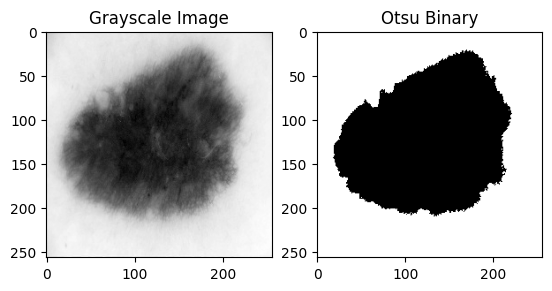

Optimal threshold T= 133.0


In [35]:
import cv2
import matplotlib.pyplot as plt

gdrive_img_path = "/content/drive/MyDrive/Colab "+ "Notebooks/computer_vision/Lab2_Dataset"
# Read image and convert to grayscale
image = cv2.imread(gdrive_img_path + "/seg_dataset/images/img_0000.jpg")
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

hist = cv2.calcHist([gray], [0], None, [256], [0, 256])

# Apply Otsu thresholding
# TODO: use cv2.threshold with cv2.THRESH_OTSU
# Solution found here: https://stackoverflow.com/questions/69416099/opencv-error-src-type-is-16-cv-8uc3-while-doing-thresh-otsu
T, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_OTSU)

plt.subplot(1,2,1)
plt.title("Grayscale Image")
plt.imshow(gray, cmap='gray')
plt.subplot(1,2,2)
plt.title("Otsu Binary")
plt.imshow(binary, cmap='gray')
plt.show()

print("Optimal threshold T=", T)

## Task 2.2: Sobel and Canny Edge Detection

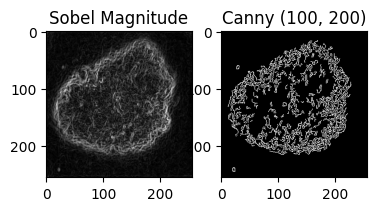

In [17]:
sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel_magnitude = np.sqrt(sobelx**2 + sobely**2).astype(np.uint8)

# Canny
# TODO: use cv2.Canny, try different threshold pairs
# canny = cv2.Canny(sobel_magnitude, 50, 100)
canny = cv2.Canny(sobel_magnitude, 100, 200)
# canny = cv2.Canny(sobel_magnitude, 150, 300)

plt.subplot(1,3,1)
plt.title("Sobel Magnitude")
plt.imshow(sobel_magnitude, cmap='gray')
plt.subplot(1,3,2)
plt.title("Canny (100, 200)")
plt.imshow(canny, cmap='gray')
plt.show()

## Task 2.3: K-Means Clustering

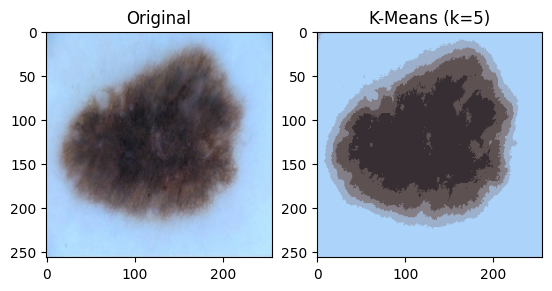

In [18]:
from sklearn.cluster import KMeans

small = cv2.resize(image, (256, 256))
pixel = small.reshape(-1,3).astype(np.float32)

# TODO: apply K-Means with k=5
k = 5
# found code here: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
kmeans = KMeans(n_clusters=k, random_state=0, n_init="auto").fit(pixel)

# found code here: https://thepythoncode.com/article/kmeans-for-image-segmentation-opencv-python
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
# _, labels, (centers) = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

# TODO: replace each pixel with its cluster centroid
_, labels, (segmented_image) = cv2.kmeans(pixel, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
segmented_image = segmented_image[labels.flatten()]
segmented_image = segmented_image.reshape(small.shape).astype(np.uint8)

plt.subplot(1,2,1)
plt.title("Original")
plt.imshow(cv2.cvtColor(small, cv2.COLOR_BGR2RGB))
plt.subplot(1,2,2)
plt.title("K-Means (k=5)")
plt.imshow(cv2.cvtColor(segmented_image, cv2.COLOR_BGR2RGB))
plt.show()


## Task 2.4: Watershed Algorithm (Robust version)

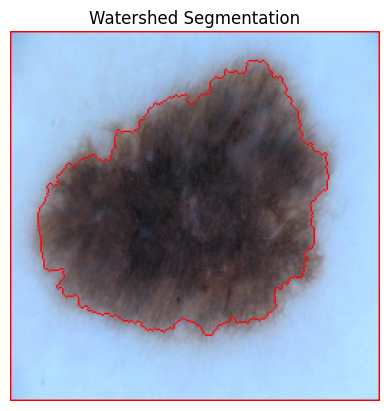

In [22]:
# Binarize
_, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Remove noise
kernel = np.ones((3,3), np.uint8)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=2)

# Sure background
sure_bg = cv2.dilate(opening, kernel, iterations=3)

# Sure foreground via distance transform
dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)

# TODO: threshold the distance transform to get sure_fg
# found code here: https://docs.opencv.org/4.13.0/d3/db4/tutorial_py_watershed.html
_, sure_fg = cv2.threshold(dist_transform,0.7*dist_transform.max(),255,0)

# Unknown region
sure_fg = np.uint8(sure_fg)
unknown = cv2.subtract(sure_bg, sure_fg)

# Marker labelling
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

# Watershed
markers = cv2.watershed(image, markers)
image[markers == -1] = [0, 0, 255]

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Watershed Segmentation")
plt.axis("off")
plt.show()

# **Part 3: Training U-Net and Using DeepLabV3**

## Task 3.1: Build and Train U-Net on a Small Dataset

In [23]:
import torch.nn as nn

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
)
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

print (f"Total parameters: {sum(p.numel() for p in model.parameters()):,} " )

Total parameters: 24,436,369 


In [248]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as T
import os
from sklearn.model_selection import train_test_split
import cv2
import numpy as np
import torch

class SegmentationDataset(Dataset):
  def __init__(self, img_dir, mask_dir, image_names, transform=None):
    self.img_dir = img_dir
    self.mask_dir = mask_dir
    self.image_names = image_names
    self.transform = transform

  def __len__(self):
    return len(self.image_names)

  def __getitem__(self, idx):
    img_name = self.image_names[idx]
    print("img_name,", img_name)
    img = Image.open(os.path.join(self.img_dir, img_name)).convert("RGB")
    mask_name = img_name.replace(".jpg", ".png")
    mask = Image.open(os.path.join(self.mask_dir, mask_name)).convert("L")

    if self.transform:
      img = self.transform(img)
      mask = self.transform(mask)

      # TODO: binarize mask (0/1) and ensure shape is (1, H, W) --> used AI
      """I tried to resize using np.reshape but T.Resize was better (via AI)
        also the last two lines of code was AI, I choose without it and it
        works but decided to keep it just in case (can always remove later). """
      mask = T.Resize((256, 256))(mask)
      _, mask = cv2.threshold(np.array(mask), 0, 255, cv2.THRESH_BINARY_INV)

      # Convert the thresholded mask back to a float32 PyTorch tensor scaled to 0 or 1
      mask = torch.tensor(mask, dtype=torch.float32) / 255.0
      # Add channel dimension to make it (1, H, W) for PyTorch training
      mask = mask.unsqueeze(0)
    return img, mask

In [249]:
# gdrive_img_path = "/content/drive/MyDrive/Colab "+ "Notebooks/computer_vision/Lab2_Dataset"
seg_img_path = gdrive_img_path + "/seg_dataset/images"
seg_mask_path = gdrive_img_path + "/seg_dataset/masks"

# print([p for p in os.listdir(seg_mask_path) if p.endswith(".png")])
# print([f for f in os.listdir(seg_img_path) if f.endswith(".jpg")])
all_imgs = sorted([f for f in os.listdir(seg_img_path) if f.endswith(".jpg")])
train_imgs, val_imgs = train_test_split(all_imgs, test_size=0.2, random_state=42)
# print("all_imag", all_imgs)
transform = T.Compose([
    T.Resize((256, 256)),
    T.ToTensor(),
])
train_dataset = SegmentationDataset(seg_img_path, seg_mask_path, train_imgs, transform)
val_dataset = SegmentationDataset(seg_img_path, seg_mask_path, val_imgs, transform)
# print(train_dataset.__getitem__(2))
# [print(j) for j in train_dataset.__getitem__(2)[1][0][0]]
# print(len(train_dataset.__getitem__(2)[1][0][0]))
# print(train_dataset.__getitem__(2)[1])
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False)

print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)}")

Train: 160 | Val: 40


In [ ]:
import torch.nn as nn
import torch.optim as optim

# Define loss function
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

num_epochs = 10

for epoch in range(num_epochs):
  # training
  model.train()
  epoch_loss = 0.0

  for images, masks in train_loader:
    images = images.to(device)
    masks = masks.to(device).float()

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, masks)
    loss.backward()
    optimizer.step()
    epoch_loss += loss.item()

  # validation
  model.eval()
  ious = []
  with torch.no_grad():
    for images, masks in val_loader:
      images = images.to(device)
      masks = masks.to(device).float()
      outputs = model(images)
      preds = (torch.sigmoid(outputs) > 0.5).float()

      # Compute IoU for this batch and append to ious
      intersection = (preds * masks).sum(dim=(2, 3))
      union = (preds + masks).clamp(0, 1).sum(dim=(2, 3))

      # Avoid division by zero
      iou = (intersection + 1e-6) / (union + 1e-6)
      ious.extend(iou.mean(dim=1).cpu().numpy().tolist())

  avg_iou = sum(ious) / len(ious) if ious else 0.0
  print(f"Epoch {epoch+1}/{num_epochs} | Loss: {epoch_loss/len(train_loader):.4f} | Val IoU: {avg_iou:.4f}")

## Task 3.2: Fully Pretrained DeepLabV3

# **Part 4: Detection -- Mask R-CNN, YOLO, DETR**

## Task 4.1: Unified Visualization Function

## Task 4.2: Mask R-CNN

## Task 4.3: YOLO vs DETR